# 05 · Supplementary EDA: supply, turnover, time-series properties, affordability, spatial clustering
**Owner:** Pricing & Availability Lead · **Needs:** steps 1b–5 done; `statsmodels` (Terminal → Run Task → *Install modelling libraries*)

Notebooks 01–02 covered prices, location and amenities. This notebook fills five gaps, each tied to a model choice:

| Section | Question | Supports |
|---|---|---|
| 1 · MOP supply wave | How many flats become resellable each year, and does resale volume follow? | SARIMAX supply regressor (Forecasting) |
| 2 · Resale rate by flat age | Do flats resell more often right after the 5-year MOP? | Survival model's start rule and age strata |
| 3 · Time-series properties | Is the price index trending, seasonal, stationary after differencing? | ARIMA/SARIMA orders (Forecasting) |
| 4 · Affordability | How far are prices running ahead of incomes? Who crosses $1 million? | The business problem |
| 5 · Spatial clustering | Is the location premium clustered in space (Moran's I)? | Block-level features; locational analytics |

In [1]:
import sys, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
import config as C
from homefit import common as K

BLUE, GREY, ORANGE = "#2a78d6", "#9a9a95", "#eb6834"
plt.rcParams.update({"figure.figsize": (10, 4.2), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.edgecolor": "#9a9a95", "axes.labelcolor": "#3d3d3a", "xtick.color": "#5c5c57",
                     "ytick.color": "#5c5c57", "lines.linewidth": 1.8, "legend.frameon": False, "font.size": 10})
TYPES = K.TYPES
s = K.sales(); s = s[s["in_scope"] & ~s["partial_month"]].copy()
s["year"] = s["month"].str[:4].astype(int)
p = pd.read_csv(C.PROPINFO, dtype={"blk_no": str}); p = p[p["residential"] == "Y"].copy()
print(f"{len(s):,} in-scope sales, {s['month'].min()} to {s['month'].max()} · {len(p):,} residential blocks, completed {p['year_completed'].min()}–{p['year_completed'].max()}")

241,407 in-scope sales, 2017-01 to 2026-09 · 10,796 residential blocks, completed 1937–2026


## 1 · The MOP supply wave
A flat can be resold 5 years after completion (the Minimum Occupation Period). HDB Property Information gives each block's
completion year and units sold by flat type, so the number of flats becoming resellable each year is known **up to 5 years ahead**.

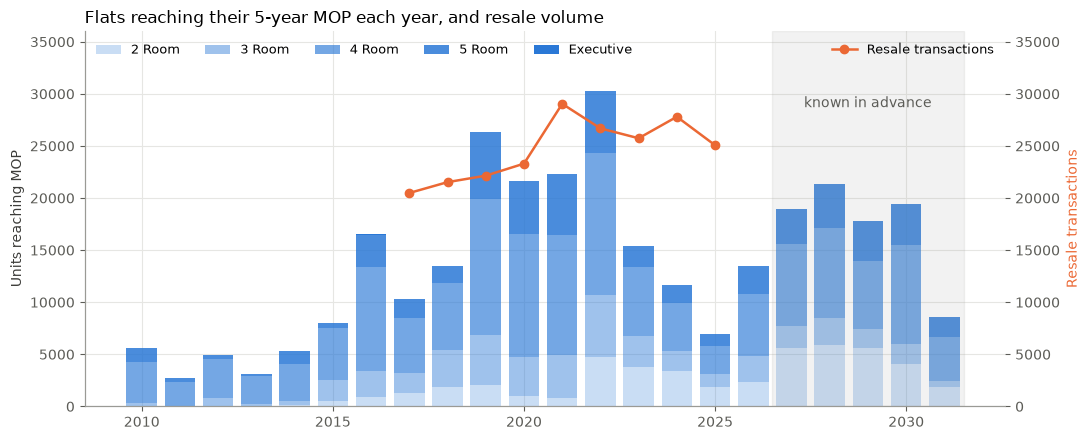

      mop_units  resales
2017      10308    20484
2018      13498    21525
2019      26335    22147
2020      21643    23300
2021      22292    29041
2022      30231    26685
2023      15372    25738
2024      11697    27801
2025       6973    25068

Correlation, units reaching MOP vs resales (2017–2025): 0.20
Units reaching MOP, 2026–2031 (known today): {2026: 13484, 2027: 18939, 2028: 21393, 2029: 17823, 2030: 19379, 2031: 8584}


In [2]:
cols = {"2room_sold": "2 ROOM", "3room_sold": "3 ROOM", "4room_sold": "4 ROOM", "5room_sold": "5 ROOM", "exec_sold": "EXECUTIVE"}
units = p.melt(id_vars=["year_completed"], value_vars=list(cols), var_name="c", value_name="units")
units["flat_type"] = units["c"].map(cols); units["mop_year"] = units["year_completed"] + 5
wave = units.groupby(["mop_year", "flat_type"])["units"].sum().unstack().reindex(columns=TYPES).loc[2010:2031]
vol = s[s["year"] <= 2025].groupby("year").size()

fig, ax = plt.subplots(figsize=(11, 4.5))
bottom = np.zeros(len(wave))
for t, a in zip(TYPES, [0.25, 0.45, 0.65, 0.85, 1.0]):
    ax.bar(wave.index, wave[t], bottom=bottom, color=BLUE, alpha=a, label=t.title()); bottom += wave[t].to_numpy()
ax.set_ylim(0, 36000); ax.axvspan(2026.5, 2031.5, color=GREY, alpha=0.12); ax.text(2029, bottom.max() * 0.95, "known in advance", ha="center", color="#5c5c57")
ax2 = ax.twinx(); ax2.plot(vol.index, vol.values, color=ORANGE, marker="o", label="Resale transactions"); ax2.grid(False)
ax2.set_ylim(0, 36000); ax2.set_ylabel("Resale transactions", color=ORANGE); ax.set_ylabel("Units reaching MOP")
ax.set_title("Flats reaching their 5-year MOP each year, and resale volume", loc="left"); ax.legend(loc="upper left", ncol=5, fontsize=9); ax2.legend(loc="upper right", fontsize=9)
plt.tight_layout(); plt.show()

tot = wave.sum(1)
both = pd.DataFrame({"mop_units": tot, "resales": vol}).dropna()
print(both.astype(int).to_string())
print(f"\nCorrelation, units reaching MOP vs resales (2017–2025): {both.corr().iloc[0, 1]:.2f}")
print("Units reaching MOP, 2026–2031 (known today):", tot.loc[2026:2031].astype(int).to_dict())

In [3]:
# Which flat types will the coming wave add?
share = wave.loc[2026:2031].sum() / wave.loc[2026:2031].sum().sum()
print("Mix of the 2026–2031 MOP wave:", (share * 100).round(1).to_dict())
print("Mix of resales, 2025:", (s[s['year'] == 2025]['flat_type'].value_counts(normalize=True).reindex(TYPES) * 100).round(1).to_dict())

Mix of the 2026–2031 MOP wave: {'2 ROOM': 25.4, '3 ROOM': 11.6, '4 ROOM': 43.0, '5 ROOM': 20.0, 'EXECUTIVE': 0.0}
Mix of resales, 2025: {'2 ROOM': 3.3, '3 ROOM': 24.5, '4 ROOM': 43.3, '5 ROOM': 23.1, 'EXECUTIVE': 5.9}


**Finding:** Units reaching MOP rose from about 10,000 in 2017 to a peak of 30,231 in 2022, then fell to 6,973 in 2025. Resale volume followed only loosely (correlation 0.20). Resales peaked in 2021 (29,041) with 22,292 units reaching MOP, and stayed high in 2024 (27,801) while MOP supply fell to 11,697. Demand-side factors moved volume as much as supply did.

A second wave is already locked in: 13,484 units reach MOP in 2026, rising to 21,393 in 2028. About 43% are 4-room and 25% are 2-room (Flexi), against 3% of resales being 2-room in 2025.

- **Forecasting:** MOP supply is a usable leading regressor because it is known 5 years ahead. On its own it explains little of annual volume, so test it with a 1-year lag alongside interest rates.
- **Availability:** the 2026–2031 wave adds 2-room and 4-room supply in newer estates, so expected waits there should shorten. The model picks this up automatically as blocks pass MOP.

## 2 · Resale rate by flat age
Sales per 100 flats of that type, by the block's age in the year of sale (2017–2025). Units = HDB Property Information's sold units,
so the rate is a turnover rate, not a count. If MOP matters, the rate should jump at age 5.

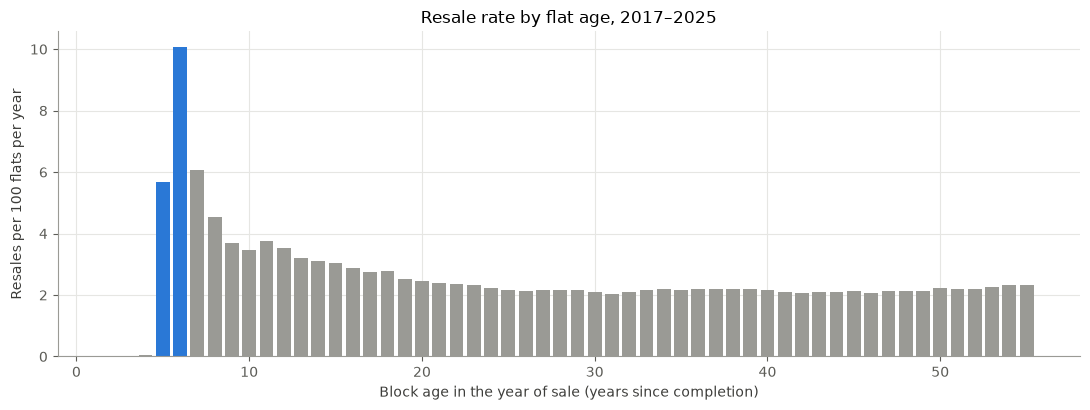

age
3      0.02
4      0.04
5      5.68
6     10.08
7      6.06
8      4.53
10     3.46
15     3.03
20     2.46
30     2.11
40     2.16
50     2.23


In [4]:
st = K.stock(); st = st[st["flat_type"].isin(TYPES)]
yrs = range(2017, 2026)
expo = pd.concat([st.assign(year=y, age=y - st["year_completed"]) for y in yrs])
expo = expo[expo["age"] >= 0]
sold = s[s["year"].isin(yrs)].drop(columns=["year_completed"], errors="ignore").merge(st[["address", "flat_type", "year_completed"]], on=["address", "flat_type"])
sold["age"] = sold["year"] - sold["year_completed"]
rate = (sold.groupby("age").size() / expo.groupby("age")["units"].sum() * 100).loc[0:55]

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(rate.index, rate.values, color=[BLUE if a in (5, 6) else GREY for a in rate.index])
ax.set(xlabel="Block age in the year of sale (years since completion)", ylabel="Resales per 100 flats per year",
       title="Resale rate by flat age, 2017–2025")
plt.tight_layout(); plt.show()
print(rate.loc[[3, 4, 5, 6, 7, 8, 10, 15, 20, 30, 40, 50]].round(2).to_string())

In [5]:
by_type = (sold.groupby(["flat_type", "age"]).size() / expo.groupby(["flat_type", "age"])["units"].sum() * 100).unstack(0).reindex(columns=TYPES)
bands = pd.cut(by_type.index, [-1, 4, 7, 14, 29, 44, 100], labels=["0-4", "5-7", "8-14", "15-29", "30-44", "45+"])
print("Mean resales per 100 flats per year, by age band:")
print(by_type.groupby(bands, observed=True).mean().round(2).to_string())

Mean resales per 100 flats per year, by age band:
flat_type  2 ROOM  3 ROOM  4 ROOM  5 ROOM  EXECUTIVE
0-4          0.01    0.04    0.02    0.02        NaN
5-7          3.48    6.78    8.14    7.75        NaN
8-14         2.82    3.55    3.73    3.56       4.05
15-29        3.40    5.23    2.30    2.50       2.83
30-44        4.34    2.36    1.89    2.09       2.81
45+          3.42    2.73    2.42    1.82       3.23


**Finding:** Resales are almost nil before age 5 (0.02–0.04 per 100 flats a year, early-sale exceptions). The rate jumps to 5.7 at age 5 and peaks at 10.1 at age 6, then decays to about 3.5 by age 10 and settles at 2.1–2.3 after age 25. The peak falls at 6, not 5, because MOP counts from key collection, which follows the completion year.

The spike holds for every flat type: 6.8–8.1 per 100 flats at ages 5–7 for 3- to 5-room, against 1.9–2.4 at ages 30–44.

This supports two survival-model choices:

1. Newer blocks start their spells at MOP eligibility, not at completion.
2. Block age is handled as strata, not as one proportional term, because the hazard spikes and then flattens.

## 3 · Time-series properties of the price index
The quality-adjusted index from step 5 (`price_index_v1.csv`, region = ALL, Jan 2017 = 100). Checks for the Forecasting Lead's
model choice: trend and seasonality (STL), stationarity (ADF and KPSS), and autocorrelation (ACF/PACF) of the monthly change.

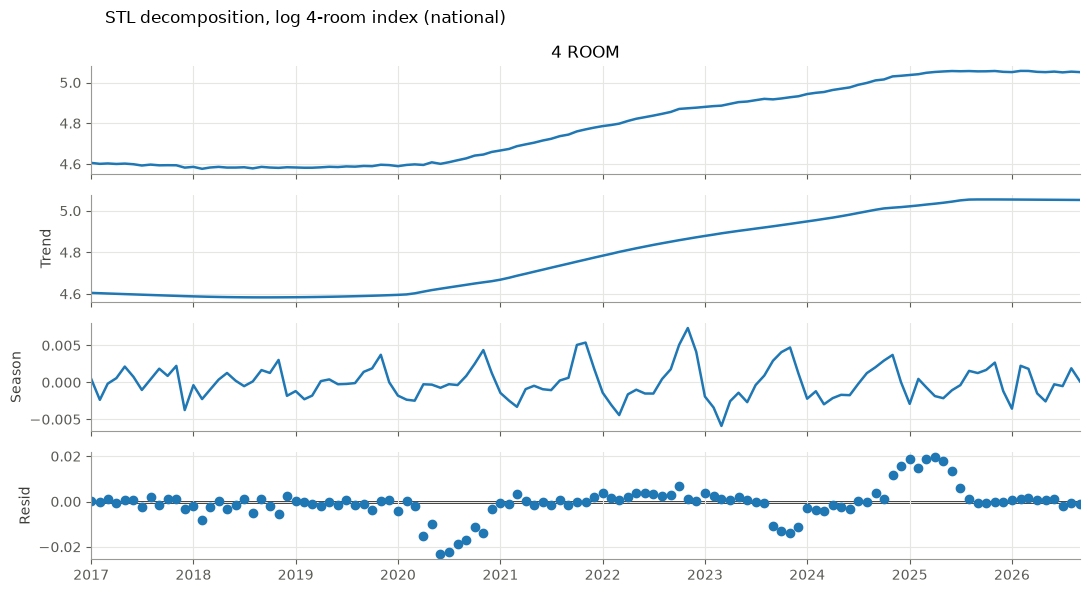

Strength of trend: 1.00 · strength of seasonality: 0.00  (0 = none, 1 = all)
Seasonal swing (max − min of the seasonal component): 1.32% of price


In [6]:
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
idx = pd.read_csv(C.OUTPUTS / "price_index_v1.csv")
idx = idx[idx["region"] == "ALL"].pivot(index="month", columns="flat_type", values="index")
idx.index = pd.PeriodIndex(idx.index, freq="M").to_timestamp()
y = np.log(idx["4 ROOM"].dropna())
stl = STL(y, period=12, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(11, 6); fig.suptitle("STL decomposition, log 4-room index (national)", x=0.1, ha="left"); plt.tight_layout(); plt.show()
var = lambda a: np.var(a)
print(f"Strength of trend: {max(0, 1 - var(stl.resid) / var(stl.trend + stl.resid)):.2f} · strength of seasonality: {max(0, 1 - var(stl.resid) / var(stl.seasonal + stl.resid)):.2f}  (0 = none, 1 = all)")
print(f"Seasonal swing (max − min of the seasonal component): {(stl.seasonal.max() - stl.seasonal.min()) * 100:.2f}% of price")

In [7]:
warnings.simplefilter('ignore')
rows = []
for t in TYPES:
    z = np.log(idx[t].dropna())
    for name, series in [("level", z), ("1st difference", z.diff().dropna()), ("2nd difference", z.diff().diff().dropna())]:
        adf_p = adfuller(series, autolag="AIC")[1]
        kpss_p = kpss(series, regression="c", nlags="auto")[1]
        rows.append({"flat_type": t, "series": name, "ADF p (H0: unit root)": round(adf_p, 3), "KPSS p (H0: stationary)": round(kpss_p, 3)})
tests = pd.DataFrame(rows)
print(tests.pivot(index="flat_type", columns="series", values=["ADF p (H0: unit root)", "KPSS p (H0: stationary)"]).reindex(TYPES).to_string())

          ADF p (H0: unit root)                       KPSS p (H0: stationary)                     
series           1st difference 2nd difference  level          1st difference 2nd difference level
flat_type                                                                                         
2 ROOM                    0.017            0.0  0.948                   0.026          0.100  0.01
3 ROOM                    0.481            0.0  0.672                   0.031          0.100  0.01
4 ROOM                    0.223            0.0  0.426                   0.030          0.100  0.01
5 ROOM                    0.492            0.0  0.722                   0.032          0.100  0.01
EXECUTIVE                 0.188            0.0  0.883                   0.049          0.076  0.01


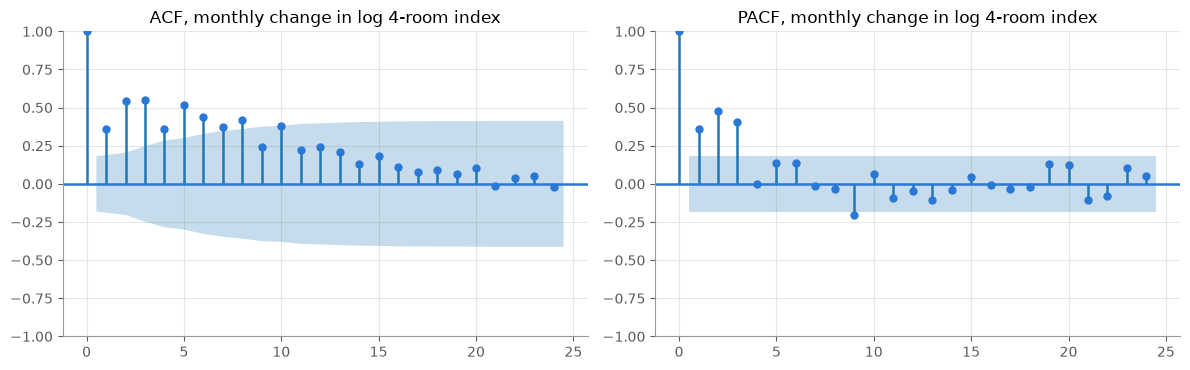

ACF lags 1-3, 12: [0.36 0.55 0.55 0.24] · PACF lags 1-3, 12: [ 0.36  0.48  0.41 -0.04] · 95% band ±0.18


In [8]:
d1 = y.diff().dropna()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
plot_acf(d1, lags=24, ax=ax[0], color=BLUE); plot_pacf(d1, lags=24, ax=ax[1], color=BLUE, method="ywm")
ax[0].set_title("ACF, monthly change in log 4-room index"); ax[1].set_title("PACF, monthly change in log 4-room index")
plt.tight_layout(); plt.show()
from statsmodels.tsa.stattools import acf, pacf
print("ACF lags 1-3, 12:", np.round(acf(d1, nlags=12)[[1, 2, 3, 12]], 2), "· PACF lags 1-3, 12:", np.round(pacf(d1, nlags=12, method='ywm')[[1, 2, 3, 12]], 2),
      f"· 95% band ±{1.96 / np.sqrt(len(d1)):.2f}")

**Finding:** The national 4-room index is almost pure trend. STL trend strength is 1.00 and seasonality 0.00; the seasonal swing is only 1.3% of price. Seasonal (SARIMA) terms are therefore unlikely to add accuracy.

- **Stationarity:** levels are non-stationary for every flat type (ADF p 0.43–0.95; KPSS rejects). After one difference, ADF still does not reject a unit root for 3- to 5-room and Executive (p 0.19–0.49), and KPSS still rejects at 5% (p ≈ 0.03). The growth rate itself drifted: it accelerated in 2020–2022 and slowed after 2024. Second differences are stationary on both tests.
- **Autocorrelation:** the monthly change shows momentum. The PACF is significant at lags 1–3 (0.36, 0.48, 0.41) and then cuts off, and the ACF decays slowly. This points to an AR(3) on first differences.

**For Forecasting:** benchmark ARIMA(3,1,0) with drift and an ARIMA(p,2,q) against the models in §6.2. A pure MA(1) on the first difference does not match this autocorrelation pattern.

## 4 · Affordability
Median resale price against median monthly household income (SingStat *Key Household Income Trends 2025*: median monthly household
**market** income, all resident households, 2020–2025; earlier years are not published on the same basis there). Price-to-income
= median price ÷ (12 × median monthly income), in years of income.

      median_price  median_4room  median_monthly_income  PTI_all  PTI_4room
year                                                                       
2017      410000.0      408000.0                    NaN      NaN        NaN
2018      408000.0      400000.0                    NaN      NaN        NaN
2019      400000.0      400000.0                    NaN      NaN        NaN
2020      425000.0      420000.0                 9099.0     3.89       3.85
2021      483000.0      470000.0                 9731.0     4.14       4.02
2022      525000.0      515000.0                10305.0     4.25       4.16
2023      550000.0      550000.0                11130.0     4.12       4.12
2024      590000.0      590000.0                11558.0     4.25       4.25
2025      628000.0      630000.0                12446.0     4.20       4.22


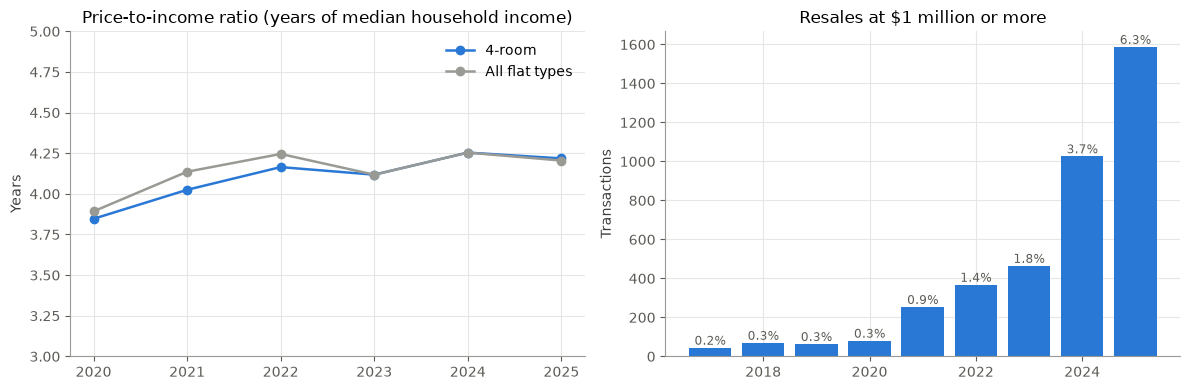

      count  share
year              
2017     45   0.22
2018     70   0.33
2019     64   0.29
2020     81   0.35
2021    254   0.87
2022    368   1.38
2023    465   1.81
2024   1027   3.69
2025   1588   6.33

$1m+ resales by flat type:
flat_type  2 ROOM  3 ROOM  4 ROOM  5 ROOM  EXECUTIVE
year                                                
2017            0       0       0      37          8
2018            0       0       9      47         14
2019            0       0      10      44         10
2020            0       0      14      55         12
2021            0       0      44     160         50
2022            0       0      38     221        109
2023            0       0     125     201        139
2024            0       0     381     392        254
2025            0       0     663     557        368


In [9]:
income = pd.Series({2020: 9099, 2021: 9731, 2022: 10305, 2023: 11130, 2024: 11558, 2025: 12446}, name="median_monthly_income")
yr = s[s["year"] <= 2025]
med = yr.groupby("year")["resale_price"].median()
med4 = yr[yr["flat_type"] == "4 ROOM"].groupby("year")["resale_price"].median()
pti = pd.DataFrame({"median_price": med, "median_4room": med4}).join(income)
pti["PTI_all"] = pti["median_price"] / (12 * pti["median_monthly_income"])
pti["PTI_4room"] = pti["median_4room"] / (12 * pti["median_monthly_income"])
print(pti.round(2).to_string())

mil = yr.assign(m=yr["resale_price"] >= 1_000_000).groupby("year")["m"].agg(["sum", "mean"])
mil_t = yr[yr["resale_price"] >= 1_000_000].groupby(["year", "flat_type"]).size().unstack(fill_value=0).reindex(columns=TYPES, fill_value=0)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(pti.dropna().index, pti.dropna()["PTI_4room"], marker="o", color=BLUE, label="4-room")
ax[0].plot(pti.dropna().index, pti.dropna()["PTI_all"], marker="o", color=GREY, label="All flat types")
ax[0].set(title="Price-to-income ratio (years of median household income)", ylabel="Years", ylim=(3, 5)); ax[0].legend()
ax[1].bar(mil.index, mil["sum"], color=BLUE); ax[1].set(title="Resales at $1 million or more", ylabel="Transactions")
for x, v, sh in zip(mil.index, mil["sum"], mil["mean"]): ax[1].text(x, v, f"{sh:.1%}", ha="center", va="bottom", fontsize=8.5, color="#5c5c57")
plt.tight_layout(); plt.show()
print(mil.assign(share=lambda d: (d["mean"] * 100).round(2)).drop(columns="mean").rename(columns={"sum": "count"}).to_string())
print("\n$1m+ resales by flat type:\n" + mil_t.to_string())

In [10]:
# Price growth vs income growth, 2020 -> 2025
g = pti.loc[2025] / pti.loc[2020] - 1
print(f"2020 -> 2025: median resale price {g['median_price']:+.0%}, 4-room {g['median_4room']:+.0%}, median household income {g['median_monthly_income']:+.0%}")

2020 -> 2025: median resale price +48%, 4-room +50%, median household income +37%


**Finding:** From 2020 to 2025 the median resale price rose 48% (4-room +50%), while median household market income rose 37%. The price-to-income ratio climbed from 3.9 to about 4.2 years of income and has stayed between 4.1 and 4.25 since 2022.

Resales at $1 million or more went from 45 (0.2% of sales) in 2017 to 1,588 (6.3%) in 2025. In 2025, 663 of them were 4-room flats, more than 5-room (557) or Executive (368). Pressure is building at the top of the market, so a fixed budget forces sharper trade-offs: exactly what the recommender prices.

Caveat: income is SingStat's median market income for all resident households, published on this basis for 2020–2025 only. The ratio is indicative, not an eligibility measure.

## 5 · Spatial clustering of the location premium (Moran's I)
The location premium from notebook 02 (price per sqm net of month × flat type, lease, storey and flat model), averaged per block.
Moran's I measures whether neighbouring blocks have similar premiums: 0 = random, near 1 = strongly clustered. Neighbours = each
block's 8 nearest blocks; significance from 199 random permutations. Run on the raw premium and on the **within-town** premium
(town mean removed), which tests whether clustering goes beyond town boundaries.

In [11]:
from scipy.spatial import cKDTree
d = s[~s["psm_outlier"]].copy()
yv = np.log(d["price_psm"]); yv = yv - yv.groupby([d["month"], d["flat_type"]]).transform("mean")
Xm = pd.concat([d[["remaining_lease_yrs", "storey_mid"]].assign(lease2=d["remaining_lease_yrs"] ** 2 / 100),
                pd.get_dummies(d["flat_model_group"], drop_first=True, dtype=float)], axis=1)
Xm = (Xm - Xm.mean()).to_numpy(float)
beta, *_ = np.linalg.lstsq(Xm, yv.to_numpy(), rcond=None)
d["premium"] = yv.to_numpy() - Xm @ beta
blk = d.groupby("address").agg(premium=("premium", "mean"), n=("premium", "size"), town=("town", "first")).join(
      K.blocks().set_index("address")[["lat", "lon"]]).query("n >= 5").dropna()
blk["premium_in_town"] = blk["premium"] - blk.groupby("town")["premium"].transform("mean")
xy = np.c_[(blk["lon"] - 103.8) * 111_320 * np.cos(np.radians(1.35)), (blk["lat"] - 1.35) * 110_574]
tree = cKDTree(xy); dist, nbr = tree.query(xy, k=9); nbr = nbr[:, 1:]

def morans_i(v, nbr, perms=199, seed=0):
    z = v - v.mean(); I = (z * z[nbr].mean(1)).sum() / (z ** 2).sum()
    rng = np.random.default_rng(seed)
    null = np.array([(zp * zp[nbr].mean(1)).sum() / (zp ** 2).sum() for zp in (rng.permutation(z) for _ in range(perms))])
    return I, (1 + (null >= I).sum()) / (perms + 1), null.mean()
res = {c: morans_i(blk[c].to_numpy(), nbr) for c in ["premium", "premium_in_town"]}
print(f"{len(blk):,} blocks with 5+ sales · median distance to the 8th nearest block: {np.median(dist[:, -1]):.0f} m")
for c, (I, pv, e) in res.items():
    print(f"Moran's I, {c:16s}: {I:.3f}  (permutation p = {pv:.3f}; expected under randomness ≈ {e:.3f})")

9,323 blocks with 5+ sales · median distance to the 8th nearest block: 150 m
Moran's I, premium         : 0.861  (permutation p = 0.005; expected under randomness ≈ 0.000)
Moran's I, premium_in_town : 0.667  (permutation p = 0.005; expected under randomness ≈ 0.000)


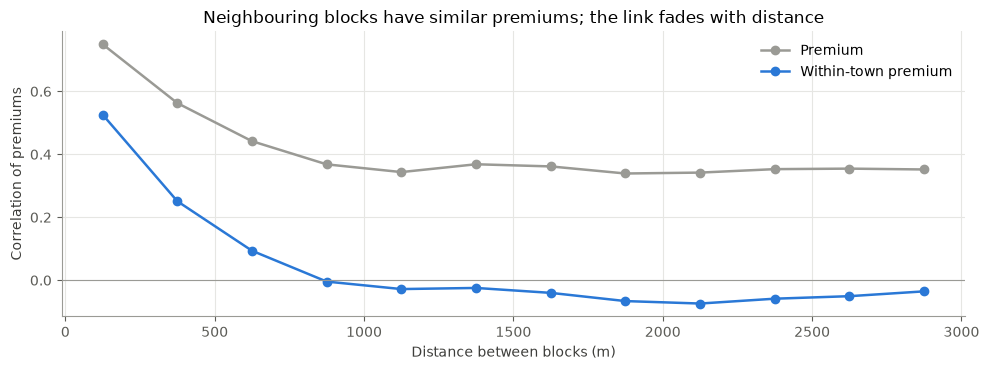

              premium  premium_in_town
(0, 250]         0.75             0.53
(250, 500]       0.56             0.25
(500, 750]       0.44             0.09
(750, 1000]      0.37            -0.00
(1000, 1250]     0.34            -0.03
(1250, 1500]     0.37            -0.02
(1500, 1750]     0.36            -0.04
(1750, 2000]     0.34            -0.07


In [12]:
# How far does the clustering reach? Correlation of premiums between block pairs, by distance band
pairs = tree.query_pairs(r=3000, output_type="ndarray")
dd = np.linalg.norm(xy[pairs[:, 0]] - xy[pairs[:, 1]], axis=1)
edges = np.arange(0, 3001, 250)
rows = []
for c in ["premium", "premium_in_town"]:
    z = (blk[c] - blk[c].mean()).to_numpy() / blk[c].std()
    prod = z[pairs[:, 0]] * z[pairs[:, 1]]
    g = pd.Series(prod).groupby(pd.cut(dd, edges)).mean()
    rows.append(g.rename(c))
corr = pd.concat(rows, axis=1)
fig, ax = plt.subplots(figsize=(10, 3.8))
mid = [iv.mid for iv in corr.index]
ax.plot(mid, corr["premium"], marker="o", color=GREY, label="Premium")
ax.plot(mid, corr["premium_in_town"], marker="o", color=BLUE, label="Within-town premium")
ax.axhline(0, color="#9a9a95", lw=0.8); ax.set(xlabel="Distance between blocks (m)", ylabel="Correlation of premiums",
       title="Neighbouring blocks have similar premiums; the link fades with distance"); ax.legend()
plt.tight_layout(); plt.show()
print(corr.round(2).head(8).to_string())

**Finding:** Moran's I is 0.861 for the block premium and 0.667 for the within-town premium. Both have p = 0.005, the smallest possible with 199 permutations; under randomness I would be about 0. Premiums cluster strongly even after removing town means.

The correlogram shows how far the clustering reaches:

- **Within-town premium:** the correlation falls from 0.53 for blocks within 250 m to 0.25 at 250–500 m and 0.09 at 500–750 m, and is about 0 beyond 750 m.
- **Raw premium:** stays around 0.35 out to 3 km, which is the town and region level.

Location value works at two scales: the town or region, and a neighbourhood of roughly 500–750 m around each block, the same scale as the MRT bands. This justifies block-level features over town averages. A neighbourhood feature (the median premium of blocks within 500 m) is a possible hedonic improvement. Because nearby sales are not independent, coefficients from linear models should use standard errors clustered by block or town.

## 6 · What this adds to the models

**Finding:** Each section changes or confirms a model choice:

| Evidence | Model choice |
|---|---|
| MOP supply is known 5 years ahead but only loosely tracks volume | Test lagged MOP supply as a SARIMAX regressor, not as the main driver |
| Resale rate spikes at ages 5–6, then flattens | Survival spells start at MOP; block age as strata |
| Index is trend-dominated, not seasonal; first differences autocorrelated at lags 1–3 | Prefer AR terms on differences; drop seasonal terms; test d = 2 |
| Prices outpaced income by 11 points in 2020–2025; $1m+ flats at 6.3% of sales | Supports the business problem and the budget constraint |
| Premiums cluster within ~750 m, beyond town effects | Block-level features; neighbourhood premium as a candidate feature |